In [1]:

import pandas as pd

df = pd.read_csv("amazon.csv")

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nReview data sample:")
print(df[['review_title', 'review_content', 'rating', 'category']].head())


Dataset shape: (1465, 16)

Column names:
['product_id', 'product_name', 'category', 'discounted_price', 'actual_price', 'discount_percentage', 'rating', 'rating_count', 'about_product', 'user_id', 'user_name', 'review_id', 'review_title', 'review_content', 'img_link', 'product_link']

Review data sample:
                                        review_title  \
0  Satisfied,Charging is really fast,Value for mo...   
1  A Good Braided Cable for Your Type C Device,Go...   
2  Good speed for earlier versions,Good Product,W...   
3  Good product,Good one,Nice,Really nice product...   
4  As good as original,Decent,Good one for second...   

                                      review_content rating  \
0  Looks durable Charging is fine tooNo complains...    4.2   
1  I ordered this cable to connect my phone to An...    4.0   
2  Not quite durable and sturdy,https://m.media-a...    3.9   
3  Good product,long wire,Charges good,Nice,I bou...    4.2   
4  Bought this instead of original apple, 

In [ ]:


%pip install vaderSentiment

import re
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

task3 = df.copy()

def clean_review(text):
    if pd.isna(text):
        return ""

    text = str(text)   
    text = re.sub(r'https?://\S+|www\.\S+', ' ', text)  
    text = re.sub(r'<[^>]+>', ' ', text)    
    text = re.sub(r'[^A-Za-z0-9\s.,!?\'-]', ' ', text)
    text = re.sub(r'\s+', ' ', text).strip()

    return text

task3['clean_review_title'] = task3['review_title'].apply(clean_review)
task3['clean_review_content'] = task3['review_content'].apply(clean_review)

print("Original review:")
print(task3['review_content'].iloc[2])

print("\nCleaned review:")
print(task3['clean_review_content'].iloc[2])

print("\nMissing review titles:", task3['clean_review_title'].eq('').sum())
print("Missing review contents:", task3['clean_review_content'].eq('').sum())


Note: you may need to restart the kernel to use updated packages.
Original review:
Not quite durable and sturdy,https://m.media-amazon.com/images/W/WEBP_402378-T1/images/I/71rIggrbUCL._SY88.jpg,Working good,https://m.media-amazon.com/images/W/WEBP_402378-T1/images/I/61bKp9YO6wL._SY88.jpg,Product,Very nice product,Working well,It's a really nice product

Cleaned review:
Not quite durable and sturdy, good, nice product,Working well,It's a really nice product

Missing review titles: 0
Missing review contents: 0



[notice] A new release of pip is available: 24.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:

analyzer = SentimentIntensityAnalyzer()

task3['combined_review'] = (
    task3['clean_review_title'] + '. ' +
    task3['clean_review_content']
).str.strip()

task3['sentiment_score'] = task3['combined_review'].apply(
    lambda text: analyzer.polarity_scores(text)['compound']
)
def classify_sentiment(score):
    if score >= 0.05:
        return 'Positive'
    elif score <= -0.05:
        return 'Negative'
    else:
        return 'Neutral'

task3['sentiment'] = task3['sentiment_score'].apply(classify_sentiment)

print(task3[['combined_review', 'sentiment_score', 'sentiment']].head(10))

print("\nSentiment counts:")
print(task3['sentiment'].value_counts())

print("\nSentiment percentages:")
print((task3['sentiment'].value_counts(normalize=True) * 100).round(2))


                                     combined_review  sentiment_score  \
0  Satisfied,Charging is really fast,Value for mo...           0.9458   
1  A Good Braided Cable for Your Type C Device,Go...           0.9947   
2  Good speed for earlier versions,Good Product,W...           0.9298   
3  Good product,Good one,Nice,Really nice product...           0.9854   
4  As good as original,Decent,Good one for second...           0.9962   
5  It's pretty good,Average quality,very good and...           0.9727   
6  Long durable.,good,Does not charge Lenovo m8 t...           0.8567   
7  Worth for money - suitable for Android auto,Go...           0.9621   
8  Works on linux for me. Get the model with ante...           0.9987   
9  A Good Braided Cable for Your Type C Device,Go...           0.9947   

  sentiment  
0  Positive  
1  Positive  
2  Positive  
3  Positive  
4  Positive  
5  Positive  
6  Positive  
7  Positive  
8  Positive  
9  Positive  

Sentiment counts:
sentiment
Positive    1

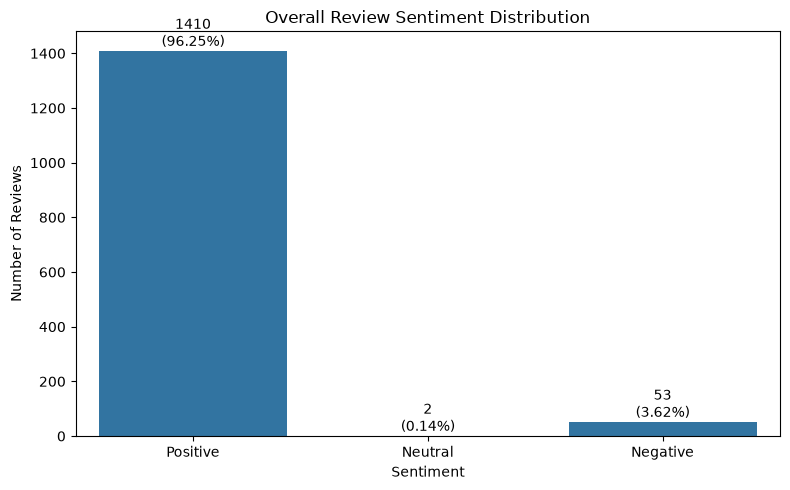

In [ ]:

import matplotlib.pyplot as plt
import seaborn as sns

sentiment_order = ['Positive', 'Neutral', 'Negative']
plt.figure(figsize=(8, 5))
ax = sns.countplot(
    data=task3,
    x='sentiment',
    order=sentiment_order
)
plt.title('Overall Review Sentiment Distribution')
plt.xlabel('Sentiment')
plt.ylabel('Number of Reviews')
total = len(task3)

for bar in ax.patches:
    count = int(bar.get_height())
    percentage = count / total * 100
    ax.annotate(
        f'{count}\n({percentage:.2f}%)',
        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        ha='center',
        va='bottom'
    )

plt.tight_layout()
plt.show()


In [ ]:

task3['main_category'] = task3['category'].str.split('|').str[0]
print("Products by main category:")
print(task3['main_category'].value_counts())
category_counts = task3['main_category'].value_counts()
major_categories = category_counts[category_counts >= 30].index
task3_major = task3[
    task3['main_category'].isin(major_categories)
].copy()
print("\nMajor categories included:")
print(task3_major['main_category'].value_counts())


Products by main category:
main_category
Electronics              526
Computers&Accessories    453
Home&Kitchen             448
OfficeProducts            31
MusicalInstruments         2
HomeImprovement            2
Toys&Games                 1
Car&Motorbike              1
Health&PersonalCare        1
Name: count, dtype: int64

Major categories included:
main_category
Electronics              526
Computers&Accessories    453
Home&Kitchen             448
OfficeProducts            31
Name: count, dtype: int64


Sentiment percentages by category:
sentiment              Positive  Neutral  Negative
main_category                                     
Computers&Accessories     96.91     0.44      2.65
Electronics               96.01     0.00      3.99
Home&Kitchen              95.76     0.00      4.24
OfficeProducts            96.77     0.00      3.23


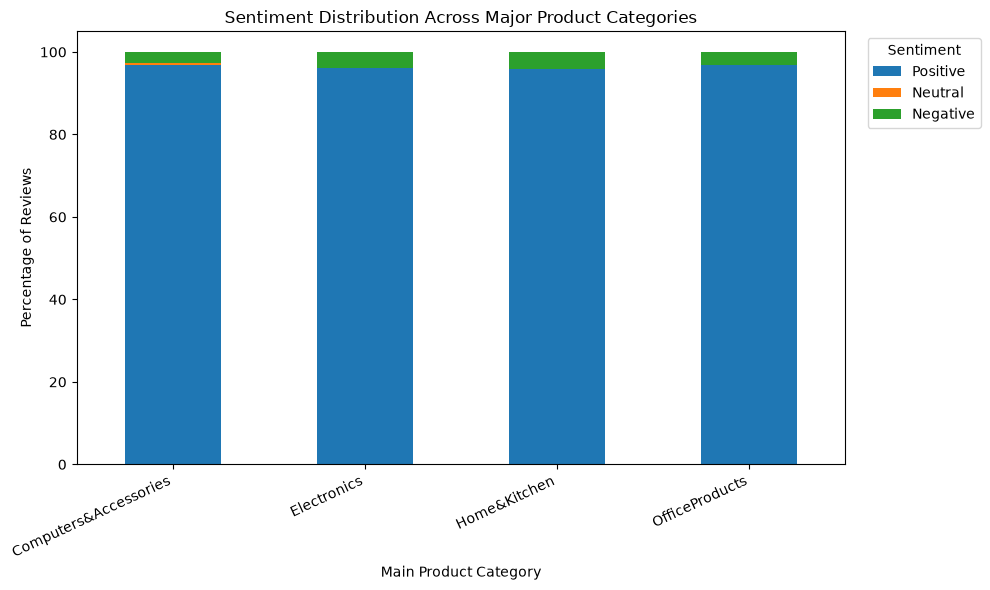

In [ ]:

sentiment_percent = pd.crosstab(
    task3_major['main_category'],
    task3_major['sentiment'],
    normalize='index'
) * 100
sentiment_percent = sentiment_percent.reindex(
    columns=['Positive', 'Neutral', 'Negative'],
    fill_value=0
)
print("Sentiment percentages by category:")
print(sentiment_percent.round(2))
sentiment_percent.plot(
    kind='bar',
    stacked=True,
    figsize=(10, 6)
)

plt.title('Sentiment Distribution Across Major Product Categories')
plt.xlabel('Main Product Category')
plt.ylabel('Percentage of Reviews')
plt.xticks(rotation=25, ha='right')
plt.legend(title='Sentiment', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()


In [ ]:

from scipy.stats import chi2_contingency
import pandas as pd

major_categories = [
    'Electronics',
    'Computers&Accessories',
    'Home&Kitchen'
]
task3_test = task3_major[
    task3_major['main_category'].isin(major_categories)
].copy()
task3_test['negative_flag'] = (
    task3_test['sentiment'] == 'Negative'
)
contingency_table = pd.crosstab(
    task3_test['main_category'],
    task3_test['negative_flag']
)
contingency_table = contingency_table.reindex(
    columns=[False, True],
    fill_value=0
)
contingency_table.columns = ['Non-negative', 'Negative']

print("Observed counts:")
print(contingency_table)

chi2, p_value, degrees_freedom, expected = chi2_contingency(
    contingency_table
)

print("\nChi-square statistic:", round(chi2, 4))
print("Degrees of freedom:", degrees_freedom)
print("P-value:", f"{p_value:.6g}")

print("\nExpected counts:")
print(pd.DataFrame(
    expected,
    index=contingency_table.index,
    columns=contingency_table.columns
).round(2))

if (expected < 5).any():
    print(
        "\nWarning: Some expected counts are below 5. "
        "Consider an exact or Monte Carlo test."
    )
else:
    if p_value < 0.05:
        print(
            "\nConclusion: Negative sentiment proportions differ "
            "significantly across the three major categories."
        )
    else:
        print(
            "\nConclusion: There is insufficient evidence that "
            "negative sentiment proportions differ across the "
            "three major categories."
        )


Observed counts:
                       Non-negative  Negative
main_category                                
Computers&Accessories           441        12
Electronics                     505        21
Home&Kitchen                    429        19

Chi-square statistic: 1.914
Degrees of freedom: 2
P-value: 0.384053

Expected counts:
                       Non-negative  Negative
main_category                                
Computers&Accessories        436.49     16.51
Electronics                  506.83     19.17
Home&Kitchen                 431.67     16.33

Conclusion: There is insufficient evidence that negative sentiment proportions differ across the three major categories.


In [ ]:

task3['rating_numeric'] = pd.to_numeric(
    task3['rating'].astype(str).str.replace(',', '.', regex=False),
    errors='coerce'
)
negative_products = task3[
    task3['sentiment'] == 'Negative'
].copy()

negative_products = negative_products.sort_values(
    'sentiment_score',
    ascending=True
)

print("Total negative-sentiment records:", len(negative_products))

print("\nMost negative products:")
print(
    negative_products[
        ['product_id', 'product_name', 'main_category',
         'rating_numeric', 'sentiment_score', 'clean_review_content']
    ].head(15).to_string(index=False)
)

print("\nNegative sentiment count by category:")
print(negative_products['main_category'].value_counts())


Total negative-sentiment records: 53

Most negative products:
product_id                                                                                                                                                                                            product_name         main_category  rating_numeric  sentiment_score                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                 

In [ ]:

high_rating_negative_text = task3[
    (task3['rating_numeric'] >= 4.0) &
    (task3['sentiment'] == 'Negative')
].copy()
low_rating_positive_text = task3[
    (task3['rating_numeric'] <= 2.0) &
    (task3['sentiment'] == 'Positive')
].copy()

print("High numerical rating but negative text:",
      len(high_rating_negative_text))

print(
    high_rating_negative_text[
        ['product_id', 'product_name', 'rating_numeric',
         'sentiment_score', 'clean_review_content']
    ].head(10).to_string(index=False)
)

print("\nLow numerical rating but positive text:",
      len(low_rating_positive_text))

print(
    low_rating_positive_text[
        ['product_id', 'product_name', 'rating_numeric',
         'sentiment_score', 'clean_review_content']
    ].head(10).to_string(index=False)
)


High numerical rating but negative text: 23
product_id                                                                                                                                           product_name  rating_numeric  sentiment_score                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                          

In [ ]:

positive_words = r'\b(good|great|excellent|love|amazing|worth|satisfied|nice)\b'
negative_words = r'\b(bad|poor|worst|broken|defective|disappointed|failed|problem)\b'

has_positive = task3['combined_review'].str.contains(
    positive_words, case=False, regex=True, na=False
)
has_negative = task3['combined_review'].str.contains(
    negative_words, case=False, regex=True, na=False
)
print("Records containing positive indicators:", int(has_positive.sum()))
print("Records containing negative indicators:", int(has_negative.sum()))
print("Records containing both:", int((has_positive & has_negative).sum()))


Records containing positive indicators: 1461
Records containing negative indicators: 625
Records containing both: 623


C:\Users\Allen\AppData\Local\Temp\ipykernel_6304\799224817.py:5: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  has_positive = task3['combined_review'].str.contains(
C:\Users\Allen\AppData\Local\Temp\ipykernel_6304\799224817.py:8: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  has_negative = task3['combined_review'].str.contains(
